# 05 · Avaliação da recuperação

O critério principal do enunciado é recuperar conteúdo relevante. Este notebook mede as estratégias de busca nas 60 perguntas respondíveis do conjunto de avaliação (`data/eval/perguntas.csv`), contra os julgamentos de relevância do pool (`data/eval/julgamentos.parquet`). A metodologia está em `docs/metodologia.md`; as métricas, em `src/evaluation/recuperacao.py`.

As seis variantes, cumulativas a partir da híbrida:

| Variante | O que muda |
|---|---|
| BM25 | só o ramo lexical |
| Vetorial | só embeddings e FAISS |
| Híbrida (RRF) | as duas listas de 50 fundidas por Reciprocal Rank Fusion |
| + re-ranking | o cross-encoder reordena os 50 candidatos |
| + filtros | filtros por metadado extraídos da pergunta por regras antes da busca |
| + HyDE | a busca vetorial usa uma avaliação hipotética escrita pelo LLM |

Todas devolvem as 10 primeiras entradas, sem MMR (o MMR é medido à parte, na seção 6).

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import time
import warnings

warnings.filterwarnings("ignore")
os.environ["TQDM_DISABLE"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.evaluation.julgamento import AUDIT, JUDGMENTS, POOL, cohen_kappa, load_questions, relevance_table
from src.evaluation.pooling import VARIANTS
from src.evaluation.recuperacao import compare, evaluate, objective_precision
from src.visualization.estilo import BLUE, GRAY, GREEN, ORANGE, RED, apply_style, fmt_pct, save

apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

questions = load_questions()
docs = pd.read_parquet("data/processed/documentos.parquet")
pool = pd.read_parquet(POOL)
judg = pd.read_parquet(JUDGMENTS)
rel = relevance_table(judg, docs, questions)
answerable = questions.loc[questions["tipo"] == "respondivel", "id"]
NOMES = {"bm25": "BM25", "vetorial": "Vetorial", "hibrida": "Híbrida (RRF)",
         "hibrida_rerank": "Híbrida + re-ranking", "hibrida_rerank_filtros": "+ filtros",
         "hibrida_rerank_filtros_hyde": "+ HyDE"}
print(f"perguntas: {len(questions)} | pares julgados: {len(judg):,} | juiz: {judg['juiz'].iloc[0]}".replace(",", "."))

perguntas: 80 | pares julgados: 2.591 | juiz: gemini-3.5-flash


## 1. O que foi julgado

O pool tem 2.591 pares pergunta e texto, julgados por `gemini-3.5-flash` numa rubrica de 0 a 2. Relevante, nas métricas principais, é nota 2 com o texto dentro do recorte anotado na pergunta.

In [2]:
por_q = rel.groupby("question_id").agg(julgados=("doc_id", "size"), nota2=("nota", lambda s: (s == 2).sum()),
                                       relevantes=("relevante", "sum"))
por_q = por_q.join(questions.set_index("id")[["tipo"]])
por_q.groupby("tipo")[["julgados", "nota2", "relevantes"]].agg(["mean", "median", "min", "max"]).round(1)

julgados                nota2                relevantes               
                           mean median min max  mean median min max       mean median min max
tipo                                                                                         
evidencia_insuficiente     29.5   29.5  24  35   1.0    1.0   0   2        0.2    0.0   0   1
fora_do_escopo             33.2   32.5  30  40   0.0    0.0   0   0        0.0    0.0   0   0
respondivel                32.9   32.0  22  46  18.4   17.5   3  38       14.8   14.5   1  29
sem_evidencia              29.2   30.0  24  32   3.8    0.0   0  14        2.0    0.0   0  14

In [3]:
print("distribuição das notas do juiz:", judg["nota"].value_counts(normalize=True).sort_index().round(3).to_dict())
fora_recorte = rel[(rel["nota"] == 2) & ~rel["no_recorte"]]
print(f"notas 2 fora do recorte anotado (não contam como relevantes): {len(fora_recorte)} de {(rel['nota'] == 2).sum()}")
nr = por_q[(por_q["tipo"] != "respondivel") & (por_q["relevantes"] > 0)]
print("perguntas não respondíveis com algum relevante no pool:", nr.index.tolist())
sem = por_q[(por_q["tipo"] == "respondivel") & (por_q["relevantes"] == 0)]
print("perguntas respondíveis sem nenhum relevante no pool:", sem.index.tolist())

distribuição das notas do juiz: {0: 0.444, 1: 0.115, 2: 0.44}
notas 2 fora do recorte anotado (não contam como relevantes): 237 de 1141
perguntas não respondíveis com algum relevante no pool: ['u13', 'u14', 'u20']
perguntas respondíveis sem nenhum relevante no pool: []


- As perguntas respondíveis têm em média 14,8 textos relevantes no pool (de 1 a 29); nenhuma ficou sem relevante. Como o recall@10 é medido contra todos os relevantes conhecidos, o teto prático dele fica perto de 0,67 (10 de 15): o valor absoluto do recall é baixo por construção, e o que importa é a comparação entre variantes.
- 237 das 1.141 notas 2 ficaram fora do recorte anotado (por exemplo, um texto sobre atraso numa pergunta restrita a cama, mesa e banho que veio de outra categoria) e não contam como relevantes.
- Três perguntas não respondíveis têm textos julgados relevantes: u13 (clientes de Portugal), u14 (atendimento por chatbot) e u20 (produtos para piscina). O juiz é instruído a ignorar restrições de região e julga só o assunto; para ele, "avaliações sobre entrega" respondem a "como os clientes de Portugal avaliam a entrega". A recusa dessas perguntas depende da análise da pergunta e do gate, medidos no notebook 06.

## 2. Ablação

In [4]:
metrics = evaluate(pool, rel, k=10)
m = metrics[metrics["question_id"].isin(answerable)]
resumo = m.groupby("variant")[["recall@10", "precision@10", "mrr"]].mean().reindex(list(VARIANTS))
resumo.index = [NOMES[v] for v in resumo.index]
resumo.round(3)

,recall@10,precision@10,mrr
BM25,0.199,0.328,0.490
Vetorial,0.240,0.385,0.554
Híbrida (RRF),0.230,0.378,0.561
Híbrida + re-ranking,0.306,0.472,0.648
+ filtros,0.500,0.693,0.860
+ HyDE,0.509,0.688,0.815


In [5]:
pares = [("bm25", "vetorial"), ("vetorial", "hibrida"), ("bm25", "hibrida"), ("hibrida", "hibrida_rerank"),
         ("hibrida_rerank", "hibrida_rerank_filtros"), ("hibrida_rerank_filtros", "hibrida_rerank_filtros_hyde")]
comp = pd.DataFrame([compare(m, a, b, met) for a, b in pares for met in ["recall@10", "precision@10", "mrr"]])
comp["comparacao"] = comp["comparacao"].map(lambda s: " - ".join(NOMES[x] for x in s.split(" - ")))
comp.round(3)

,comparacao,metrica,diferenca,ic95_inf,ic95_sup,significativa
0,Vetorial - BM25,recall@10,0.041,-0.021,0.100,False
1,Vetorial - BM25,precision@10,0.057,-0.027,0.138,False
2,Vetorial - BM25,mrr,0.064,-0.049,0.177,False
3,Híbrida (RRF) - Vetorial,recall@10,-0.010,-0.045,0.028,False
4,Híbrida (RRF) - Vetorial,precision@10,-0.007,-0.053,0.045,False
5,Híbrida (RRF) - Vetorial,mrr,0.007,-0.075,0.091,False
6,Híbrida (RRF) - BM25,recall@10,0.031,-0.011,0.071,False
7,Híbrida (RRF) - BM25,precision@10,0.050,0.002,0.100,True
8,Híbrida (RRF) - BM25,mrr,0.071,-0.029,0.173,False
9,Híbrida + re-ranking - Híbrida (RRF),recall@10,0.076,0.032,0.124,True


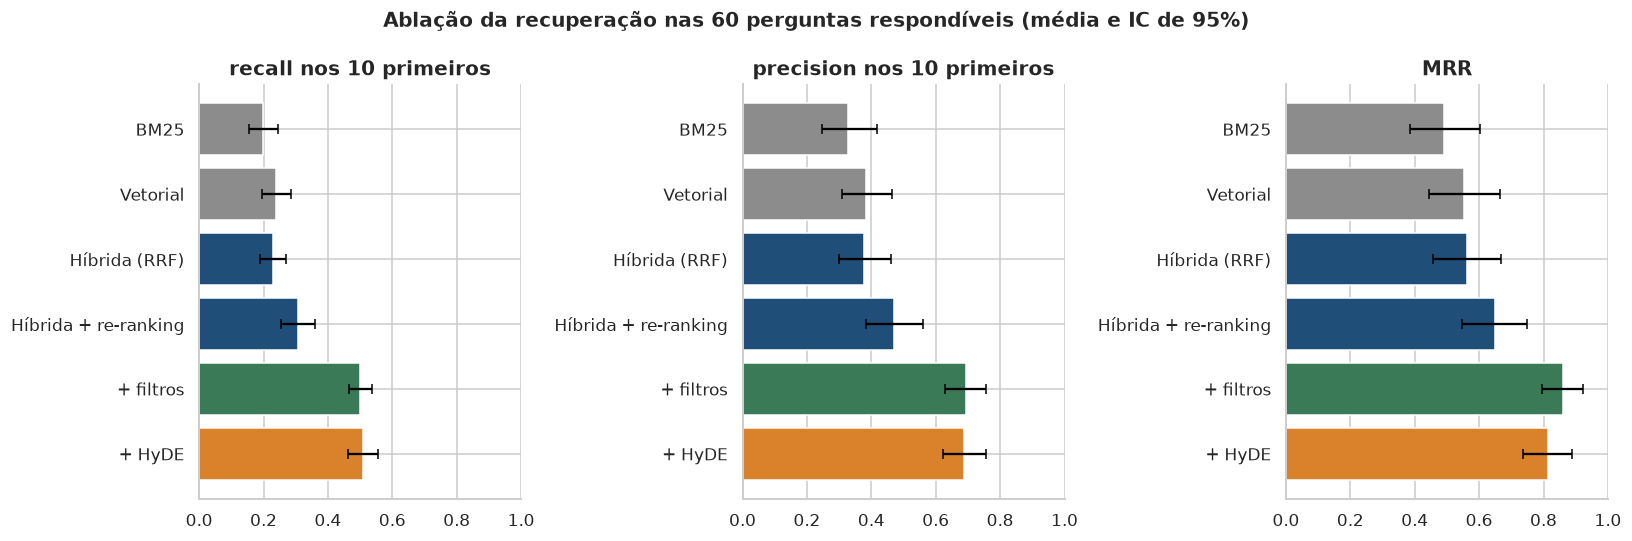

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
cores = [GRAY, GRAY, BLUE, BLUE, GREEN, ORANGE]
for ax, met in zip(axes, ["recall@10", "precision@10", "mrr"]):
    wide = m.pivot(index="question_id", columns="variant", values=met)[list(VARIANTS)]
    means = wide.mean()
    rng = np.random.default_rng(0)
    boots = np.array([wide.iloc[rng.integers(0, len(wide), len(wide))].mean() for _ in range(2000)])
    lo, hi = np.nanpercentile(boots, 2.5, axis=0), np.nanpercentile(boots, 97.5, axis=0)
    ax.barh([NOMES[v] for v in VARIANTS][::-1], means.values[::-1], color=cores[::-1],
            xerr=[(means.values - lo)[::-1], (hi - means.values)[::-1]], capsize=3)
    ax.set(title=met.replace("@10", " nos 10 primeiros").replace("mrr", "MRR"), xlim=(0, 1))
fig.suptitle("Ablação da recuperação nas 60 perguntas respondíveis (média e IC de 95%)", fontweight="bold", fontsize=13)
save(fig, "05_ablacao_recuperacao");

**Leitura da ablação:**

- **BM25 contra vetorial contra híbrida:** nenhuma diferença significativa entre os três em MRR e recall. A híbrida supera o BM25 em precisão (+0,05, IC de 0,00 a 0,10) e empata com o vetorial. **A fusão em si não trouxe ganho mensurável neste conjunto**; isso fica como limitação de D07. A busca híbrida continua no pipeline por dois motivos: nenhum ramo domina entre tipos de pergunta (na tabela da seção 4, o vetorial vence nas perguntas do enunciado e o BM25 nas de tema), e o re-ranking trabalha sobre os candidatos dos dois ramos.
- **Re-ranking:** é o primeiro ganho significativo. Precision@10 sobe 0,09 (IC de 0,05 a 0,14) e recall@10, 0,08; o MRR sobe 0,09, com intervalo que toca o zero. O custo é de cerca de 1 segundo a mais por pergunta em CPU. **D08 confirmada.**
- **Filtros:** o maior ganho, em todas as métricas (MRR de 0,65 para 0,86). Parte desse ganho vem da definição de relevância, que exige o recorte anotado nas perguntas de metadado, e as regras de filtro foram ajustadas lendo estas perguntas. Por isso a seção 4 separa as perguntas que não dependem de metadado.
- **HyDE:** não acrescenta. Recall e precisão ficam iguais e o MRR cai 0,045 (IC de -0,10 a 0,01). Custa uma chamada ao LLM por pergunta. **HyDE fica fora do pipeline final**; a transformação da pergunta fica a cargo da reescrita feita na análise, medida no notebook 06.

## 3. Precisão objetiva, sem juiz

Para as perguntas sobre atraso (q12, q15, q17, q48, q59) e não recebimento (q16, q56), a fração dos 10 primeiros cujas avaliações pertencem ao grupo do metadado.

In [7]:
alvo = questions[questions["alvo_objetivo"] != ""]
grupo = {
    "atraso": (docs["delivery_status"] == "atrasada").groupby(docs["doc_id"]).mean(),
    "nao_recebeu": (docs["delivery_status"].isin(["nao entregue", "cancelada"]) | docs["answered_before_delivery"]).groupby(docs["doc_id"]).mean(),
}
linhas = []
for _, q in alvo.iterrows():
    for v in VARIANTS:
        ranked = pool[(pool.question_id == q["id"]) & (pool.variant == v)].sort_values("rank")["doc_id"].tolist()
        linhas.append({"pergunta": q["id"], "alvo": q["alvo_objetivo"], "variante": NOMES[v],
                       "precisao_objetiva@10": objective_precision(ranked, grupo[q["alvo_objetivo"]], 10)})
obj = pd.DataFrame(linhas)
print("taxa base: atraso", round(grupo["atraso"].mean(), 3), "| não recebeu", round(grupo["nao_recebeu"].mean(), 3))
obj.pivot_table(index="variante", columns="alvo", values="precisao_objetiva@10", aggfunc="mean").reindex([NOMES[v] for v in VARIANTS]).round(3)

taxa base: atraso 0.097 | não recebeu 0.129


alvo,atraso,nao_recebeu
variante,,
BM25,0.320,0.45
Vetorial,0.473,0.30
Híbrida (RRF),0.461,0.30
Híbrida + re-ranking,0.376,0.45
+ filtros,0.821,1.00
+ HyDE,0.841,1.00


Com filtros, 82% a 84% dos resultados das perguntas de atraso são de fato de pedidos atrasados (taxa base de 10%) e 100% dos de não recebimento pertencem ao grupo (taxa base de 13%). Sem filtro, a melhor variante fica em 47% e 45%. A medida não depende do juiz e confirma o ganho dos filtros onde a pergunta pede um recorte de entrega.

## 4. Sensibilidade

Com a leitura tolerante de relevância (nota 1 ou 2), a ordem das variantes é a mesma. Por origem da pergunta (MRR):

In [8]:
tol = evaluate(pool, rel, k=10, column="parcial_ou_mais")
tol = tol[tol["question_id"].isin(answerable)].groupby("variant")[["recall@10", "precision@10", "mrr"]].mean().reindex(list(VARIANTS))
tol.index = [NOMES[v] for v in tol.index]
tol.round(3)

,recall@10,precision@10,mrr
BM25,0.213,0.423,0.573
Vetorial,0.242,0.507,0.638
Híbrida (RRF),0.232,0.480,0.643
Híbrida + re-ranking,0.295,0.558,0.715
+ filtros,0.493,0.838,0.958
+ HyDE,0.503,0.847,0.944


In [9]:
por_origem = m.merge(questions[["id", "origem"]], left_on="question_id", right_on="id")
po = por_origem.pivot_table(index="variant", columns="origem", values="mrr", aggfunc="mean").reindex(list(VARIANTS))
po.index = [NOMES[v] for v in po.index]
po.round(3)

origem,enunciado,metadado,tema
BM25,0.502,0.179,0.732
Vetorial,0.779,0.206,0.698
Híbrida (RRF),0.706,0.224,0.745
Híbrida + re-ranking,0.607,0.347,0.913
+ filtros,0.856,0.762,0.940
+ HyDE,0.663,0.722,0.980


In [10]:
sem_meta = m[m["question_id"].isin(questions.loc[questions["origem"].isin(["enunciado", "tema"]), "id"])]
pd.DataFrame([compare(sem_meta, "hibrida_rerank", "hibrida_rerank_filtros", met) for met in ["recall@10", "precision@10", "mrr"]]).assign(
    comparacao="+ filtros - Híbrida + re-ranking (só enunciado e tema)").round(3)

,comparacao,metrica,diferenca,ic95_inf,ic95_sup,significativa
0,+ filtros - Híbrida + re-ranking (só enunciado e tema),recall@10,0.059,0.023,0.102,True
1,+ filtros - Híbrida + re-ranking (só enunciado e tema),precision@10,0.090,0.040,0.150,True
2,+ filtros - Híbrida + re-ranking (só enunciado e tema),mrr,0.110,0.040,0.195,True


**Sem as perguntas de metadado (40 perguntas do enunciado e de tema), os filtros continuam ajudando:** precision@10 +0,09 (IC de 0,04 a 0,15) e MRR +0,11 (IC de 0,04 a 0,19). Nessas perguntas o filtro é só o de nota ("problemas" e "reclamações" restringem a notas até 3; "elogios", a 4 e 5), e ele tira da lista os textos do mesmo assunto com o sinal trocado, o mesmo efeito que o notebook 02 previa (60% dos comentários que falam de entrega são elogios). Nas perguntas de metadado, o ganho é de 0,42 em MRR, e aí a maior parte vem do recorte.

**D09 confirmada**, com a ressalva de que o extrator de filtros do pipeline final é o LLM, não as regras; o notebook 06 mede o extrator do LLM contra o recorte anotado.

## 5. Concordância do juiz

Amostra de 120 pares julgada também por um segundo modelo, de outra família (`gemma-4-26b-a4b-it`).

In [11]:
audit = pd.read_csv(AUDIT, keep_default_na=False)
a, b = audit["nota_juiz"].to_numpy(), audit["nota_segundo_juiz"].to_numpy()
print(f"pares: {len(audit)} | concordância exata: {np.mean(a == b):.1%} | kappa de Cohen: {cohen_kappa(a, b):.3f}")
bin_a, bin_b = a == 2, b == 2
print(f"relevante (nota 2) x não relevante: concordância {np.mean(bin_a == bin_b):.1%} | kappa {cohen_kappa(bin_a, bin_b):.3f}")
print(pd.crosstab(pd.Series(a, name="juiz principal"), pd.Series(b, name="segundo juiz")))
manual = audit[audit["nota_manual"].astype(str).str.strip() != ""]
if len(manual):
    mm = manual["nota_manual"].astype(int).to_numpy()
    print(f"\nauditoria manual: {len(manual)} pares | concordância com o juiz {np.mean(mm == manual['nota_juiz']):.1%} | kappa {cohen_kappa(mm, manual['nota_juiz'].to_numpy()):.3f}")
else:
    print("\nauditoria manual: coluna nota_manual ainda não preenchida")

pares: 120 | concordância exata: 65.0% | kappa de Cohen: 0.430
relevante (nota 2) x não relevante: concordância 70.0% | kappa 0.421
segundo juiz     0  1   2
juiz principal           
0               23  3   7
1                3  7  24
2                4  1  48

auditoria manual: coluna nota_manual ainda não preenchida


In [12]:
disc = audit[audit["nota_juiz"] != audit["nota_segundo_juiz"]]
disc[["question_id", "pergunta", "texto", "nota_juiz", "nota_segundo_juiz"]].head(8)

,question_id,pergunta,texto,nota_juiz,nota_segundo_juiz
1,q03,O que os consumidores mais valorizam em sua experiência de compra?,excelente experiência de compra. Obrigado,1,2
2,q03,O que os consumidores mais valorizam em sua experiência de compra?,"Mais respeito ao consumidor, era para presente!",0,1
9,q07,O que os clientes mais elogiam em suas experiências de compra?,"Tanto vendedor como loja, excelentes, gosto muito de comprar pela baratheonr",1,2
12,q08,Quais problemas são relatados por clientes insatisfeitos?,Empresa sem compromisso com o cliente,1,2
18,q10,O que os clientes relatam sobre problemas relacionados à entrega?,Embora tenha havido problemas com a entrega pelos correios o produto chegou.,1,2
24,q16,O que os clientes dizem quando o pedido não chega?,"Infelizmente, encontramos na internet, lojas que para poderem vender, dizem ...",1,2
27,q16,O que os clientes dizem quando o pedido não chega?,"Entrega sem informações. Apesar dos produtos da loja serem de bom custo, o t...",1,2
28,q20,Há reclamações de produtos que chegaram quebrados ou danificados?,Mandei email com reclamação de que meu produto estava com a etiqueta/código ...,1,2


**Concordância moderada:** 65% de concordância exata e kappa de 0,43; no recorte binário que as métricas usam (relevante ou não), 70% e kappa de 0,42. A discordância se concentra entre "parcial" e "relevante": em 24 dos 42 desacordos, o juiz principal deu 1 e o segundo deu 2. O juiz principal é mais exigente, o que deixa as métricas acima do lado conservador. Os exemplos mostram textos genéricos ("excelente experiência de compra") que um juiz considera evidência e o outro não.

**Limitação declarada:** a auditoria humana da amostra (coluna `nota_manual` de `data/eval/auditoria_manual.csv`) ainda não foi preenchida. Quando for, a célula acima calcula a concordância do juiz com ela. Até lá, a validade do juiz se apoia na concordância moderada entre dois modelos de famílias diferentes.

## 6. Latência e diversidade

In [13]:
from src.retrieval.filtros import rule_based_filters
from src.retrieval.hibrida import Retriever
from src.retrieval.hyde import hyde_vector
from src.retrieval.reranking import CrossEncoderReranker

retriever = Retriever.load(CrossEncoderReranker())
hyde = dict(pd.read_parquet("data/eval/hyde.parquet").values)
amostra = questions[questions["tipo"] == "respondivel"].sample(12, random_state=1)
lat = []
for _, q in amostra.iterrows():
    for v, (mode, rerank, filt, use_hyde) in VARIANTS.items():
        t0 = time.perf_counter()
        f = rule_based_filters(q["pergunta"]) if filt else None
        qv = hyde_vector(hyde[q["id"]]) if use_hyde else None
        retriever.retrieve(q["pergunta"], f, mode=mode, k=10, rerank=rerank, mmr_lambda=None, query_vector=qv)
        lat.append({"variante": NOMES[v], "ms": 1000 * (time.perf_counter() - t0)})
lat = pd.DataFrame(lat).groupby("variante", sort=False)["ms"].median().round(0)
lat.to_frame("mediana em ms (sem a chamada do HyDE ao LLM)")

,mediana em ms (sem a chamada do HyDE ao LLM)
variante,
BM25,159.0
Vetorial,162.0
Híbrida (RRF),201.0
Híbrida + re-ranking,1535.0
+ filtros,1501.0
+ HyDE,1499.0


In [14]:
def diversidade(ids):
    pos = [retriever.position[d] for d in ids]
    V = retriever.vector.vectors[pos]
    S = V @ V.T
    return S[np.triu_indices(len(ids), 1)].mean() if len(ids) > 1 else np.nan

judged = set(zip(rel["question_id"], rel["doc_id"]))
linhas = []
for _, q in questions[questions["tipo"] == "respondivel"].iterrows():
    f = rule_based_filters(q["pergunta"])
    sem_mmr = retriever.retrieve(q["pergunta"], f, k=10, rerank=True, mmr_lambda=None)
    com_mmr = retriever.retrieve(q["pergunta"], f, k=10, rerank=True, mmr_lambda=0.7)
    rel_q = set(rel[(rel.question_id == q["id"]) & rel["relevante"]]["doc_id"])
    for nome, hits in [("sem MMR", sem_mmr), ("com MMR", com_mmr)]:
        ids = [h.doc_id for h in hits]
        linhas.append({"variante": nome, "similaridade_media_top10": diversidade(ids),
                       "precision@10": sum(d in rel_q for d in ids) / 10,
                       "nao_julgados": sum((q["id"], d) not in judged for d in ids) / 10})
mmr = pd.DataFrame(linhas).groupby("variante").mean().round(3)
mmr

,similaridade_media_top10,precision@10,nao_julgados
variante,,,
com MMR,0.489,0.658,0.042
sem MMR,0.532,0.693,0.000


In [15]:
tabela = resumo.copy()
tabela["latencia_mediana_ms"] = lat.reindex(tabela.index).values
tabela.insert(0, "variante", [k for k in VARIANTS])
Path("reports").mkdir(exist_ok=True)
tabela.round(4).to_csv("reports/ablacao_recuperacao.csv", index_label="nome")
tabela.round(3)

,variante,recall@10,precision@10,mrr,latencia_mediana_ms
BM25,bm25,0.199,0.328,0.490,159.0
Vetorial,vetorial,0.240,0.385,0.554,162.0
Híbrida (RRF),hibrida,0.230,0.378,0.561,201.0
Híbrida + re-ranking,hibrida_rerank,0.306,0.472,0.648,1535.0
+ filtros,hibrida_rerank_filtros,0.500,0.693,0.860,1501.0
+ HyDE,hibrida_rerank_filtros_hyde,0.509,0.688,0.815,1499.0


- **Latência:** BM25, vetorial e híbrida ficam abaixo de 0,2 s; o re-ranking leva a busca para 1 a 1,5 s em CPU (a medida varia com a carga da máquina entre execuções). O HyDE soma a isso uma chamada ao LLM (4,5 s em média na geração dos textos), sem ganho.
- **MMR:** com λ = 0,7, a similaridade média entre os 10 resultados cai de 0,53 para 0,49, e a precision@10 cai de 0,69 para 0,66. Parte da queda vem de 4,2% dos resultados com MMR que nunca foram julgados e contam como não relevantes. O MMR fica no pipeline final, porque o contexto do LLM ganha variedade de relatos, e o custo de 3,5 pontos de precisão fica declarado.

## 7. O que fica decidido

| Decisão | Evidência |
|---|---|
| D07 busca híbrida mantida, com limitação | empata com o vetorial (diferenças não significativas); nenhum ramo domina entre tipos de pergunta |
| D08 re-ranking com cross-encoder | precision@10 +0,09 e recall@10 +0,08, significativos; custo de cerca de 1 s por pergunta |
| D09 filtros por metadado | MRR +0,21 no geral, +0,11 nas perguntas sem metadado; precisão objetiva de 82% a 100% contra 45% a 47% sem filtro |
| D25 HyDE fora do pipeline final | sem ganho significativo e MRR 0,045 menor, ao custo de uma chamada ao LLM |
| MMR com λ = 0,7 no contexto | redundância menor, precisão 3,5 pontos menor |

Configuração final da recuperação: filtros, BM25 e vetorial fundidos por RRF, re-ranking dos 50 candidatos e MMR nos 10 que vão ao LLM. A tabela da ablação fica em `reports/ablacao_recuperacao.csv`.